## Import packages and configure paths

In [1]:
# %pip install lightgbm scikit-learn joblib

In [2]:
from pathlib import Path
import time
import gc

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_log_error
)

from config import PROCESSED_DIR, FIGURE_DIR, TABLE_DIR, MODEL_DIR

In [3]:
data_file = (
    PROCESSED_DIR / "electricity_data.parquet"
).as_posix()

con = duckdb.connect()
con.execute("SET memory_limit = '4GB'")
con.execute("SET threads = 2")

RANDOM_STATE = 42

print("LightGBM version:", lgb.__version__)
print("Dataset exists:", Path(data_file).exists())

LightGBM version: 4.7.0
Dataset exists: True


## Define modeling features

In [4]:
# Building and calendar features
base_features = [
    "building_id",
    "site_id",
    "primary_use",
    "square_feet",
    "hour",
    "day_of_week",
    "month"
]

# Weather-related features
weather_features = [
    "air_temperature",
    "dew_temperature",
    "wind_speed"
]

# Complete predictor set
all_features = base_features + weather_features

categorical_features = [
    "building_id",
    "site_id",
    "primary_use"
]

target = "meter_reading"

print("Predictors:", all_features)
print("Target:", target)

Predictors: ['building_id', 'site_id', 'primary_use', 'square_feet', 'hour', 'day_of_week', 'month', 'air_temperature', 'dew_temperature', 'wind_speed']
Target: meter_reading


## Create chronological datasets

In [5]:
columns = all_features + [target]

column_sql = ", ".join(columns)

# Sample training observations reproducibly.
# HASH determines which training rows are selected.
train_query = f"""
SELECT {column_sql}
FROM read_parquet(?)
WHERE timestamp < TIMESTAMP '2016-10-01'
  AND HASH(building_id, timestamp) % 100 < 12
"""

validation_query = f"""
SELECT {column_sql}
FROM read_parquet(?)
WHERE timestamp >= TIMESTAMP '2016-10-01'
  AND timestamp < TIMESTAMP '2016-12-01'
"""

test_query = f"""
SELECT {column_sql}
FROM read_parquet(?)
WHERE timestamp >= TIMESTAMP '2016-12-01'
"""

train_df = con.execute(
    train_query, [data_file]
).df()

val_df = con.execute(
    validation_query, [data_file]
).df()

test_df = con.execute(
    test_query, [data_file]
).df()

print("Training sample:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training sample: (1000011, 11)
Validation: (1887642, 11)
Test: (943555, 11)


## Prepare data types

In [6]:
datasets = [train_df, val_df, test_df]

numeric_features = [
    "square_feet",
    "hour",
    "day_of_week",
    "month",
    "air_temperature",
    "dew_temperature",
    "wind_speed"
]

# Use a common category definition across datasets.
for feature in categorical_features:
    categories = pd.Index(
        pd.concat(
            [df[feature] for df in datasets],
            ignore_index=True
        ).dropna().unique()
    )

    for df in datasets:
        df[feature] = pd.Categorical(
            df[feature],
            categories=categories
        )

# Reduce numeric memory usage
for df in datasets:
    for feature in numeric_features:
        df[feature] = df[feature].astype("float32")

    df[target] = df[target].astype("float32")

    assert (df[target] >= 0).all()

print("Data prepared successfully.")

Data prepared successfully.


## Define evaluation metrics

In [7]:
def evaluate_model(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)

    mae = mean_absolute_error(
        y_true, y_pred
    )

    rmsle = np.sqrt(
        mean_squared_log_error(
            y_true, y_pred
        )
    )

    return {
        "MAE": round(mae, 4),
        "RMSLE": round(rmsle, 4)
    }

# Train and evaluate the models

## Historical baseline prediction

In [8]:
# Historical median for each building and hour
baseline_table = (
    train_df
    .groupby(
        ["building_id", "hour"],
        observed=True
    )[target]
    .median()
    .rename("baseline_prediction")
    .reset_index()
)

# Fallback for an unseen building-hour combination
building_median = (
    train_df
    .groupby("building_id", observed=True)[target]
    .median()
)

global_median = train_df[target].median()

def baseline_predict(df):
    result = df[
        ["building_id", "hour"]
    ].merge(
        baseline_table,
        on=["building_id", "hour"],
        how="left",
        sort=False
    )

    predictions = result["baseline_prediction"]

    predictions = predictions.fillna(
        df["building_id"].map(building_median).reset_index(drop=True)
    )

    return predictions.fillna(global_median).to_numpy()

baseline_val_pred = baseline_predict(val_df)

baseline_results = evaluate_model(
    val_df[target],
    baseline_val_pred
)

print("Historical baseline:", baseline_results)

Historical baseline: {'MAE': 39.5386, 'RMSLE': np.float64(0.8758)}


## Train LightGBM without weather variables

In [9]:
X_train_base = train_df[base_features]
X_val_base = val_df[base_features]

y_train = np.log1p(train_df[target])
y_val = val_df[target].to_numpy()

model_params = {
    "objective": "regression",
    "n_estimators": 200,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "max_bin": 127,
    "n_jobs": 2,
    "verbosity": -1,
    "random_state": RANDOM_STATE
}

model_base = lgb.LGBMRegressor(**model_params)

start = time.perf_counter()

model_base.fit(
    X_train_base,
    y_train,
    categorical_feature=categorical_features
)

base_training_time = time.perf_counter() - start

base_log_pred = model_base.predict(X_val_base)

base_pred = np.maximum(
    np.expm1(base_log_pred), 0
)

base_results = evaluate_model(
    y_val, base_pred
)

print("Without weather:", base_results)
print("Training time:", round(base_training_time, 2), "seconds")

Without weather: {'MAE': 39.9785, 'RMSLE': np.float64(0.72)}
Training time: 8.74 seconds


## Train LightGBM with weather variables

In [10]:
X_train_all = train_df[all_features]
X_val_all = val_df[all_features]

model_weather = lgb.LGBMRegressor(**model_params)

start = time.perf_counter()

model_weather.fit(
    X_train_all,
    y_train,
    categorical_feature=categorical_features
)

weather_training_time = time.perf_counter() - start

weather_log_pred = model_weather.predict(X_val_all)

weather_pred = np.maximum(
    np.expm1(weather_log_pred), 0
)

weather_results = evaluate_model(
    y_val, weather_pred
)

print("With weather:", weather_results)
print("Training time:", round(weather_training_time, 2), "seconds")

With weather: {'MAE': 35.6227, 'RMSLE': np.float64(0.693)}
Training time: 9.36 seconds


## Compare validation results

In [11]:
comparison = pd.DataFrame([
    {
        "Model": "Historical Baseline",
        **baseline_results,
        "Training Time (s)": 0.0
    },
    {
        "Model": "LightGBM without Weather",
        **base_results,
        "Training Time (s)": round(base_training_time, 2)
    },
    {
        "Model": "LightGBM with Weather",
        **weather_results,
        "Training Time (s)": round(weather_training_time, 2)
    }
])

display(comparison)

comparison.to_csv(
    TABLE_DIR / "validation_results.csv",
    index=False
)

,Model,MAE,RMSLE,Training Time (s)
0,Historical Baseline,39.5386,0.8758,0.00
1,LightGBM without Weather,39.9785,0.7200,8.74
2,LightGBM with Weather,35.6227,0.6930,9.36


# Final evaluation using December 2016

## Evaluate on the final test data

In [12]:
# Select the LightGBM configuration based on validation RMSLE
if weather_results["RMSLE"] < base_results["RMSLE"]:
    final_model = model_weather
    final_features = all_features
    selected_name = "LightGBM with Weather"
else:
    final_model = model_base
    final_features = base_features
    selected_name = "LightGBM without Weather"

print("Selected configuration:", selected_name)

# Predict December electricity consumption
test_log_pred = final_model.predict(
    test_df[final_features]
)

test_pred = np.maximum(
    np.expm1(test_log_pred), 0
)

# Baseline evaluation on the same test records
baseline_test_pred = baseline_predict(test_df)

test_results = evaluate_model(
    test_df[target],
    test_pred
)

baseline_test_results = evaluate_model(
    test_df[target],
    baseline_test_pred
)

final_results = pd.DataFrame([
    {
        "Model": "Historical Baseline",
        **baseline_test_results
    },
    {
        "Model": selected_name,
        **test_results
    }
])

display(final_results)

final_results.to_csv(
    TABLE_DIR / "final_test_results.csv",
    index=False
)

Selected configuration: LightGBM with Weather


,Model,MAE,RMSLE
0,Historical Baseline,45.6112,0.7841
1,LightGBM with Weather,41.0431,0.6221


## Plot actual versus predicted electricity consumption

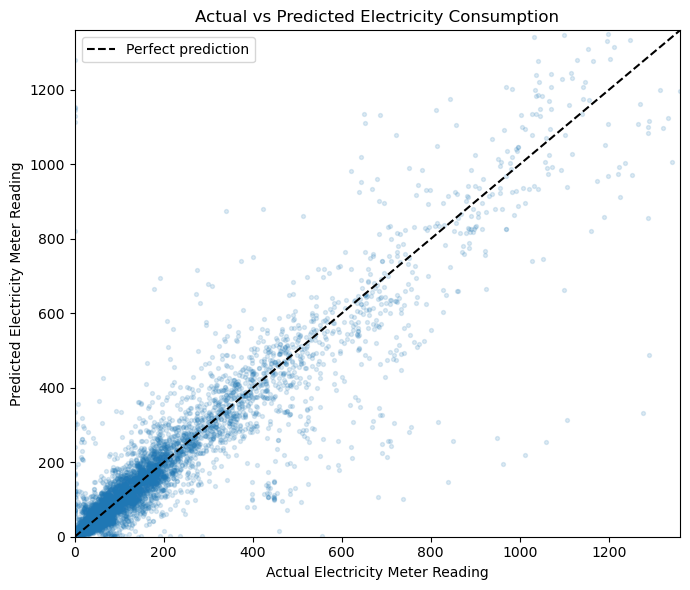

In [15]:
rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(10000, len(test_df))

indices = rng.choice(
    len(test_df),
    size=sample_size,
    replace=False
)

actual = test_df[target].to_numpy()[indices]
predicted = test_pred[indices]

plt.figure(figsize=(7, 6))

plt.scatter(
    actual,
    predicted,
    alpha=0.15,
    s=8
)

limit = np.percentile(
    np.concatenate([actual, predicted]), 99
)

plt.plot(
    [0, limit],
    [0, limit],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Perfect prediction"
)

plt.xlim(0, limit)
plt.ylim(0, limit)

plt.xlabel("Actual Electricity Meter Reading")
plt.ylabel("Predicted Electricity Meter Reading")
plt.title("Actual vs Predicted Electricity Consumption")

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "actual_vs_predicted_electricity_prediction.png",
    bbox_inches="tight"
)

plt.show()

## Save the model

In [14]:
model_file = MODEL_DIR / "electricity_lightgbm.joblib"

joblib.dump(
    {
        "model": final_model,
        "features": final_features,
        "model_name": selected_name,
        "parameters": model_params,
        "training_period": "2016-01 to 2016-09",
        "validation_period": "2016-10 to 2016-11",
        "test_period": "2016-12"
    },
    model_file
)

print("Model saved to:", model_file)

Model saved to: D:\Big Data Project\outputs\models\electricity_lightgbm.joblib
